<a href="https://colab.research.google.com/github/KarlaMichelleSorianoSanhez/Simulacion-II/blob/main/SIR_Bayesiano_PyMC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<h1><font color="#D97706">Ajuste de parámetros del modelo SIR mediante inferencia bayesiana</font></h1>

**Materia:** Simulación II

**Instrucciones:** Resolver el ajuste de parámetros del modelo SIR utilizando un enfoque bayesiano y la biblioteca PyMC de Python. Explicar el enfoque y la interpretación de las gráficas obtenidas.

<h2><font color="#D97706">Objetivo</font></h2>

Estimar los parámetros de transmisión y recuperación del modelo SIR a partir de los datos de un brote de influenza, utilizando inferencia bayesiana con PyMC. También se analizará la convergencia de las cadenas de Markov y el comportamiento del modelo ajustado.

<h2><font color="#D97706">1. Preparación del entorno de trabajo</font></h2>

Utilizaremos PyMC para construir el modelo bayesiano y obtener muestras de las distribuciones posteriores. También emplearemos ArviZ para analizar las cadenas y representar los resultados.

In [1]:
# Instalamos PyMC y ArviZ para el análisis bayesiano
%pip install -q pymc arviz

<h2><font color="#D97706">2. Planteamiento del problema</font></h2>

En el artículo *The inverse problem of a dynamical system solved with genetic algorithms* se estudia un brote de influenza en un internado con 763 estudiantes. A partir de los registros de infectados durante 15 días, los autores buscan estimar los parámetros del modelo SIR.

En esta actividad resolveremos el mismo problema, pero utilizando inferencia bayesiana en lugar de algoritmos genéticos.

Nuestro propósito es estimar los parámetros $a$ y $b$, y conocer la incertidumbre asociada a sus valores mediante las distribuciones posteriores.

<h2><font color="#D97706">3. Modelo matemático SIR</font></h2>

El modelo SIR divide a la población en tres grupos: susceptibles ($S$), infectados ($I$) y recuperados o retirados ($R$).

De acuerdo con el artículo, el sistema está formado por las ecuaciones diferenciales:

$$
\begin{aligned}
\frac{dS}{dt} &= -aSI,\\[6pt]
\frac{dI}{dt} &= aSI-bI,\\[6pt]
\frac{dR}{dt} &= bI.
\end{aligned}
$$

Donde:

- $a$: parámetro de transmisión.
- $b$: tasa de recuperación.

La primera ecuación describe la disminución de susceptibles debido a los contagios. La segunda considera los nuevos contagios y las recuperaciones. La tercera representa el aumento de personas recuperadas.

Como se supone una población cerrada, el número total de estudiantes permanece constante:

$$
S(t)+I(t)+R(t)=N=763.
$$

Por lo tanto:

$$
\frac{dS}{dt}+\frac{dI}{dt}+\frac{dR}{dt}=0.
$$

<h2><font color="#D97706">4. Datos observados</font></h2>

Utilizaremos los 15 registros de infectados presentados en la Tabla 1 del artículo.

Al inicio del registro se tiene un estudiante infectado. Supondremos que los demás son susceptibles y que todavía no hay recuperados, por lo que las condiciones iniciales serán:

$$
S(0)=762,\qquad I(0)=1,\qquad R(0)=0.
$$

Estos datos serán la base para estimar los parámetros del modelo.

In [2]:
# Biblioteca para trabajar con arreglos numéricos
import numpy as np

# Número total de estudiantes
N = 763

# Días registrados en el artículo
t = np.arange(15)

# Número de infectados observados
I_obs = np.array([
    1, 3, 6, 25, 73, 222, 294, 258,
    237, 191, 125, 69, 27, 11, 4
])

# Condiciones iniciales
S0 = 762
I0 = 1
R0 = 0

y0 = [S0, I0, R0]

# Mostramos los datos
print("Días:", t)
print("Infectados:", I_obs)

Días: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14]
Infectados: [  1   3   6  25  73 222 294 258 237 191 125  69  27  11   4]


<h3><font color="#D97706">4.1. Comportamiento de los datos observados</font></h3>

Antes de realizar el ajuste, representaremos los datos para observar cómo cambia el número de infectados durante el brote.

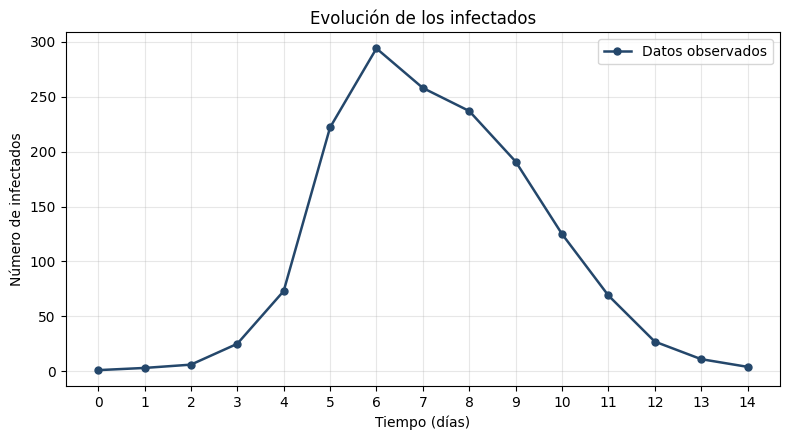

In [3]:
# Biblioteca para elaborar gráficas
import matplotlib.pyplot as plt

# Graficamos los datos de infectados
plt.figure(figsize=(8, 4.5))

plt.plot(
    t, I_obs,
    "o-",
    color="#24476B",
    linewidth=1.8,
    markersize=5,
    label="Datos observados"
)

plt.title("Evolución de los infectados")
plt.xlabel("Tiempo (días)")
plt.ylabel("Número de infectados")

plt.xticks(t)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

**Observación:** El número de infectados aumenta hasta alcanzar un máximo de 294 estudiantes en el día 6. Después comienza a disminuir, hasta registrar 4 infectados en el último día.

Este comportamiento será el que buscaremos reproducir mediante el modelo SIR.

<h2><font color="#D97706">5. Solución numérica del modelo SIR</font></h2>

El sistema SIR no tiene una solución analítica explícita general, por lo que lo resolveremos numéricamente con `solve_ivp` de SciPy.

Primero utilizaremos los parámetros reportados mediante algoritmos genéticos en el artículo:

$$
a=0.00205,\qquad b=0.43552.
$$

Estos valores servirán para comprobar el comportamiento del modelo. Posteriormente estimaremos nuestros propios parámetros mediante PyMC.

In [4]:
# Biblioteca para resolver ecuaciones diferenciales
from scipy.integrate import solve_ivp

# Definimos las ecuaciones del modelo SIR
def sir(t, y, a, b):

    S, I, R = y

    dS = -a * S * I
    dI = a * S * I - b * I
    dR = b * I

    return [dS, dI, dR]


# Parámetros de referencia del artículo
a_ref = 0.00205
b_ref = 0.43552

# Resolvemos el sistema en los días observados
solucion = solve_ivp(
    sir,
    t_span=(t[0], t[-1]),
    y0=y0,
    t_eval=t,
    args=(a_ref, b_ref),
    rtol=1e-8,
    atol=1e-10
)

# Verificamos que la solución se haya obtenido
if not solucion.success:
    raise RuntimeError(solucion.message)

# Separamos los tres grupos
S_ref, I_ref, R_ref = solucion.y

# Comprobamos que la población se conserve
print("Población inicial:", N)
print(
    "Población al día 14:",
    round(S_ref[-1] + I_ref[-1] + R_ref[-1], 4)
)

Población inicial: 763
Población al día 14: 763.0


<h3><font color="#D97706">5.1. Comportamiento del modelo SIR</font></h3>

Representaremos las soluciones de susceptibles, infectados y recuperados. También agregaremos los datos observados para comparar el comportamiento de la curva de infectados.

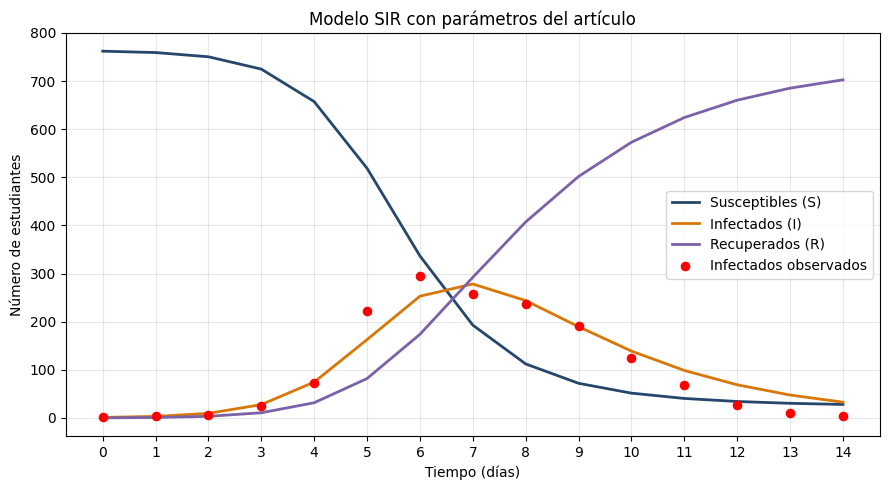

In [5]:
# Biblioteca para elaborar gráficas
import matplotlib.pyplot as plt

# Graficamos las soluciones del modelo
plt.figure(figsize=(9, 5))

plt.plot(t, S_ref, color="#24476B",
         linewidth=2, label="Susceptibles (S)")

plt.plot(t, I_ref, color="#D97706",
         linewidth=2, label="Infectados (I)")

plt.plot(t, R_ref, color="#7B61A8",
         linewidth=2, label="Recuperados (R)")

# Agregamos los datos observados
plt.scatter(
    t, I_obs,
    color="red",
    s=35,
    zorder=3,
    label="Infectados observados"
)

plt.title("Modelo SIR con parámetros del artículo")
plt.xlabel("Tiempo (días)")
plt.ylabel("Número de estudiantes")

plt.xticks(t)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

**Observación:** El modelo muestra una disminución de susceptibles y un aumento de recuperados. Los infectados presentan un crecimiento inicial y después disminuyen.

La curva sigue una tendencia similar a los datos observados, aunque existen diferencias entre algunos valores. Por ello, utilizaremos inferencia bayesiana para estimar los parámetros y analizar la incertidumbre del ajuste.

<h2><font color="#D97706">6. Enfoque bayesiano</font></h2>

La inferencia bayesiana permite estimar parámetros combinando la información que tenemos antes de analizar los datos con la información que estos proporcionan.

De acuerdo con Sivia y Skilling, este procedimiento se basa en el teorema de Bayes:

$$
p(a,b\mid D)=\frac{p(D\mid a,b)\,p(a,b)}{p(D)}.
$$

En nuestro problema:

- **Distribución a priori, $p(a,b)$:** representa la información inicial sobre los parámetros.
- **Verosimilitud, $p(D\mid a,b)$:** indica qué tan compatibles son los datos observados con los valores de $a$ y $b$.
- **Distribución posterior, $p(a,b\mid D)$:** representa la información actualizada sobre los parámetros después de considerar los datos.
- **Evidencia, $p(D)$:** permite normalizar la distribución posterior.

Como la evidencia no depende directamente de los parámetros que queremos estimar, podemos escribir:

$$
p(a,b\mid D)\propto p(D\mid a,b)\,p(a,b).
$$

Así, podremos obtener distribuciones para $a$ y $b$, en lugar de calcular únicamente un valor para cada parámetro.

<h3><font color="#D97706">6.1. Distribuciones a priori (prior)</font></h3>

Los parámetros $a$ y $b$ deben ser positivos porque describen la transmisión y la recuperación de la enfermedad.

Para nuestro análisis utilizaremos distribuciones uniformes independientes:

$$
a\sim U(0,0.01),
$$

$$
b\sim U(0,1).
$$

Esto significa que, antes de utilizar los datos, consideraremos igualmente posibles los valores dentro de cada intervalo.

Para $a$ elegimos un intervalo pequeño porque el término de contagio del modelo depende del producto $SI$. Para $b$ consideramos valores entre 0 y 1 por día.

Estos intervalos son supuestos de nuestro modelo bayesiano, no resultados obtenidos del artículo.

<h3><font color="#D97706">6.2. Verosimilitud (likelihood)</font></h3>

La verosimilitud permite relacionar los datos observados con los valores que predice el modelo SIR.

Para cada combinación de $a$ y $b$, resolveremos las ecuaciones diferenciales y obtendremos el número esperado de infectados $I(t_i;a,b)$.

Como nuestros datos son conteos de estudiantes infectados, utilizaremos una distribución de Poisson:

$$
I_{\mathrm{obs}}(t_i)\mid a,b
\sim
\operatorname{Poisson}\left(I(t_i;a,b)\right).
$$

Su función de probabilidad es:

$$
p(y_i\mid a,b)=
\frac{e^{-\lambda_i}\lambda_i^{y_i}}{y_i!},
$$

donde:

$$
y_i=I_{\mathrm{obs}}(t_i),
\qquad
\lambda_i=I(t_i;a,b).
$$

De esta manera, los valores de $a$ y $b$ que producen curvas más compatibles con los datos tendrán mayor verosimilitud.

Utilizaremos las observaciones de los días 1 al 14, porque el día 0 ya está definido como condición inicial del sistema.

<h3><font color="#D97706">6.3. Distribución posterior (posterior)</font></h3>

La distribución posterior se obtiene al combinar las distribuciones a priori con la verosimilitud mediante el teorema de Bayes:

$$
p(a,b\mid D)\propto p(D\mid a,b)\,p(a)\,p(b).
$$

En nuestro caso, la verosimilitud se construye a partir de los datos de los días 1 al 14:

$$
p(D\mid a,b)=\prod_{i=1}^{14}p(y_i\mid a,b).
$$

La distribución posterior nos permitirá conocer qué valores de $a$ y $b$ son más compatibles con los datos y cuál es la incertidumbre asociada a su estimación.

Como resulta complicado calcular esta distribución directamente, utilizaremos PyMC para obtener muestras mediante MCMC.

<h3><font color="#D97706">6.4. Muestreo mediante MCMC</font></h3>

Los métodos de Monte Carlo mediante cadenas de Markov (MCMC) permiten obtener muestras de una distribución de probabilidad sin necesidad de calcularla directamente.

Utilizaremos el algoritmo NUTS de PyMC, que aprovecha las derivadas de la distribución posterior para explorar los valores de los parámetros.

Trabajaremos con cuatro cadenas independientes. Antes del muestreo definitivo realizaremos una prueba corta para comprobar el tiempo de ejecución.

Después analizaremos la convergencia utilizando:

- **$\hat R$:** permite comparar el comportamiento de las cadenas.
- **ESS:** indica cuántas muestras efectivamente independientes contiene aproximadamente el muestreo.
- **Divergencias:** ayudan a identificar dificultades durante la exploración de la distribución posterior.

También revisaremos las gráficas de las cadenas. Si los diagnósticos son adecuados, podremos utilizar las muestras para estimar los parámetros y construir las gráficas finales.

<h2><font color="#D97706">7. Implementación numérica del modelo SIR</font></h2>

Para utilizar el modelo SIR dentro de PyMC, necesitamos resolver sus ecuaciones diferenciales para distintos valores de $a$ y $b$.

Emplearemos el método de Runge-Kutta de cuarto orden (RK4), dividiendo cada día en cinco pasos numéricos.

Además, utilizaremos `scan` de PyTensor para realizar los cálculos de manera más compacta y permitir que PyMC obtenga las derivadas necesarias durante el muestreo.

In [6]:
# Bibliotecas para operaciones simbólicas compatibles con PyMC
import numpy as np
import pytensor
import pytensor.tensor as pt

# Definimos las ecuaciones del modelo SIR
def ecuaciones_sir(y, a, b):

    S, I, R = y[0], y[1], y[2]

    dS = -a * S * I
    dI = a * S * I - b * I
    dR = b * I

    return pt.stack([dS, dI, dR])


# Un paso del método de Runge-Kutta de cuarto orden
def paso_rk4(y, a, b, h):

    k1 = ecuaciones_sir(y, a, b)
    k2 = ecuaciones_sir(y + h*k1/2, a, b)
    k3 = ecuaciones_sir(y + h*k2/2, a, b)
    k4 = ecuaciones_sir(y + h*k3, a, b)

    return y + (h/6)*(k1 + 2*k2 + 2*k3 + k4)


# Función que resuelve el SIR durante 14 días
def resolver_sir(a, b):

    # Condiciones iniciales
    y_inicial = pt.as_tensor_variable(
        np.array([S0, I0, R0], dtype="float64")
    )

    # Cinco pasos numéricos por día
    pasos_por_dia = 5
    h = 1.0 / pasos_por_dia

    # Calculamos la evolución del sistema
    trayectoria = pytensor.scan(
        fn=lambda y, a, b: paso_rk4(y, a, b, h),
        outputs_info=y_inicial,
        non_sequences=[a, b],
        n_steps=14 * pasos_por_dia,
        strict=True,
        return_updates=False
    )

    # Guardamos la solución al finalizar cada día
    soluciones = pt.concatenate(
        [
            y_inicial[None, :],
            trayectoria[pasos_por_dia-1::pasos_por_dia]
        ],
        axis=0
    )

    return soluciones

<h3><font color="#D97706">7.1. Comprobación de la solución numérica</font></h3>

Compararemos la solución obtenida mediante RK4 con la de `solve_ivp`, utilizando los parámetros de referencia del artículo.

Calcularemos la diferencia máxima entre ambas soluciones para verificar que la reducción de pasos numéricos no produzca cambios considerables en los resultados.

In [7]:
# Bibliotecas para evaluar los cálculos
import numpy as np
import pytensor
import pytensor.tensor as pt

# Variables simbólicas para los parámetros
a_sim = pt.dscalar("a_sim")
b_sim = pt.dscalar("b_sim")

# Preparamos la función numérica de PyTensor
evaluar_rk4 = pytensor.function(
    [a_sim, b_sim],
    resolver_sir(a_sim, b_sim)
)

# Resolvemos con los parámetros de referencia
solucion_rk4 = evaluar_rk4(a_ref, b_ref)

# Comparamos con solve_ivp, calculado anteriormente
diferencia = np.max(
    np.abs(solucion.y.T - solucion_rk4)
)

diferencia_I = np.max(
    np.abs(I_ref - solucion_rk4[:, 1])
)

print("Diferencia máxima del sistema:", round(diferencia, 6))
print("Diferencia máxima de infectados:", round(diferencia_I, 6))

# Comprobamos que se conserve la población
poblacion_rk4 = solucion_rk4.sum(axis=1)

print(
    "Error de conservación de población:",
    np.max(np.abs(poblacion_rk4 - N))
)

Diferencia máxima del sistema: 0.01081
Diferencia máxima de infectados: 0.006384
Error de conservación de población: 2.2737367544323206e-13


<h2><font color="#D97706">8. Construcción del modelo bayesiano en PyMC</font></h2>

Una vez comprobada la solución numérica, incorporaremos las distribuciones a priori y la verosimilitud de Poisson.

PyMC evaluará los parámetros $a$ y $b$, resolverá el modelo SIR y comparará el número esperado de infectados con los datos observados.

De esta manera construiremos la distribución posterior de ambos parámetros.

In [8]:
# Biblioteca para construir el modelo probabilístico
import pymc as pm

with pm.Model() as modelo_sir:

    # Distribuciones a priori
    a = pm.Uniform("a", lower=0, upper=0.01)
    b = pm.Uniform("b", lower=0, upper=1)

    # Resolvemos el modelo SIR
    solucion_modelo = resolver_sir(a, b)

    # Número esperado de infectados en los días 1 a 14
    I_modelo = pm.Deterministic(
        "I_modelo",
        pt.maximum(solucion_modelo[1:, 1], 1e-8)
    )

    # Verosimilitud de Poisson
    pm.Poisson(
        "infectados",
        mu=I_modelo,
        observed=I_obs[1:]
    )

print("Modelo bayesiano construido correctamente.")

Modelo bayesiano construido correctamente.


<h3><font color="#D97706">8.1. Muestreo de la distribución posterior</font></h3>

Para obtener muestras de la distribución posterior de los parámetros $a$ y $b$, utilizaremos el algoritmo NUTS de PyMC.

Trabajaremos con cuatro cadenas de Markov, cada una con 500 iteraciones de adaptación y 1000 muestras posteriores.

Las iteraciones de adaptación permiten ajustar el algoritmo y después se descartan. Las cuatro cadenas nos ayudarán a comprobar si el muestreo explora de manera adecuada la misma distribución.

Al finalizar, revisaremos los diagnósticos de convergencia para determinar si las muestras obtenidas son suficientes.

In [10]:
# Bibliotecas para el muestreo y la medición del tiempo
import pymc as pm
import time
from google.colab import drive

# Conectamos Google Drive para guardar los resultados
drive.mount("/content/drive")

# Registramos el tiempo inicial
inicio = time.perf_counter()

# Realizamos el muestreo de la distribución posterior
with modelo_sir:

    idata = pm.sample(
        draws=1000,          # Muestras posteriores por cadena
        tune=500,            # Iteraciones de adaptación
        chains=4,            # Cuatro cadenas de Markov
        cores=2,             # Ejecutamos dos cadenas en paralelo
        target_accept=0.9,   # Probabilidad objetivo de aceptación
        random_seed=42,     # Semilla para reproducir los resultados
        return_inferencedata=True
    )

# Calculamos el tiempo transcurrido
duracion = time.perf_counter() - inicio

print(f"Tiempo del muestreo: {duracion/60:.2f} minutos")

# Guardamos las muestras para utilizarlas posteriormente
ruta = "/content/drive/MyDrive/SIR_muestras.nc"

idata.to_netcdf(ruta)

print("Muestras guardadas correctamente.")

Mounted at /content/drive


Output()

Tiempo del muestreo: 3.25 minutos
Muestras guardadas correctamente.


<h2><font color="#D97706">9. Análisis de convergencia</font></h2>

Después del muestreo, revisaremos si las cuatro cadenas presentan una convergencia adecuada.

Para ello utilizaremos los siguientes diagnósticos:

- **$\hat R$:** compara el comportamiento de las cadenas. Buscaremos valores menores que 1.01.
- **ESS:** indica la cantidad efectiva de muestras que aporta el muestreo.
- **Divergencias:** permiten identificar posibles dificultades durante la exploración de la distribución posterior.

También analizaremos las gráficas de las cadenas antes de interpretar los parámetros estimados.

In [11]:
# Biblioteca para analizar las muestras posteriores
import arviz as az

# Calculamos el resumen de los parámetros
resumen = az.summary(
    idata,
    var_names=["a", "b"],
    hdi_prob=0.95,
    round_to=6
)

print(resumen)

# Revisamos el número total de divergencias
divergencias = int(idata.sample_stats["diverging"].sum())

print("\nNúmero de divergencias:", divergencias)

       mean       sd  hdi_2.5%  hdi_97.5%  mcse_mean   mcse_sd     ess_bulk  \
a  0.002212  0.00002  0.002174   0.002254   0.000000  0.000000  2596.368881   
b  0.480987  0.01110  0.458321   0.501826   0.000219  0.000174  2562.126032   

      ess_tail     r_hat  
a  2081.981239  1.000258  
b  2320.599296  1.000412  

Número de divergencias: 0


<h3><font color="#D97706">9.1. Gráficas de convergencia</font></h3>

Representaremos las distribuciones y las trayectorias de las cuatro cadenas para los parámetros $a$ y $b$.

Las distribuciones permitirán comparar los valores explorados por cada cadena, mientras que las trazas mostrarán su comportamiento a lo largo de las iteraciones.

Buscaremos que las cadenas se mezclen, presenten distribuciones similares y no mantengan tendencias durante el muestreo.

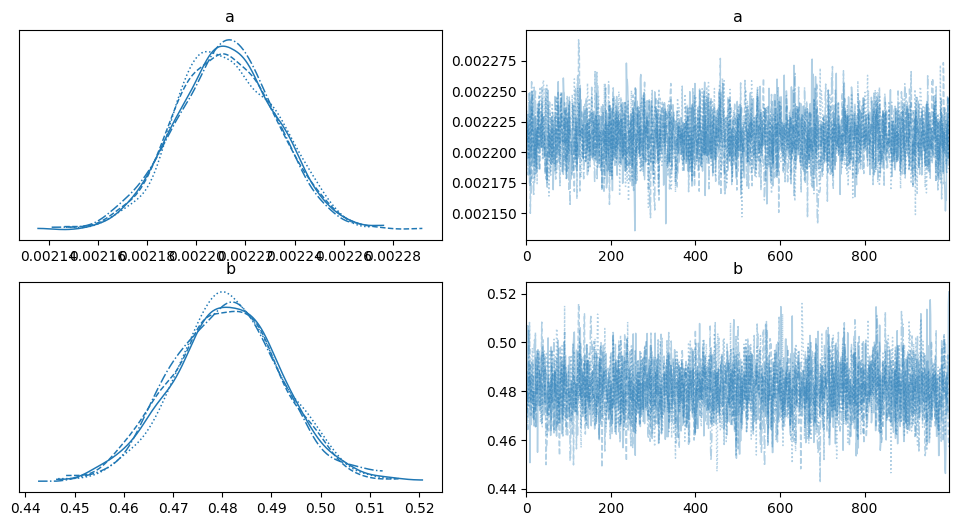

In [12]:
# Bibliotecas para analizar y graficar las cadenas
import arviz as az
import matplotlib.pyplot as plt

# Graficamos las distribuciones y las trazas
az.plot_trace(
    idata,
    var_names=["a", "b"],
    figsize=(12, 6)
)

plt.show()

**Observación:** Las cuatro cadenas presentan distribuciones similares y se mantienen estables durante el muestreo. Los valores de $\hat R$ son cercanos a 1, los tamaños efectivos de muestra son adecuados y no se registraron divergencias. Por lo tanto, los resultados indican una buena convergencia y podemos continuar con el análisis de los parámetros estimados.

<h2><font color="#D97706">10. Distribuciones posteriores de los parámetros</font></h2>

Una vez comprobada la convergencia, analizaremos las distribuciones posteriores de $a$ y $b$.

Estas distribuciones permiten identificar los valores más probables de los parámetros y la incertidumbre asociada a sus estimaciones.

Para cada parámetro representaremos su distribución posterior, la media y el intervalo de credibilidad del 95 %.

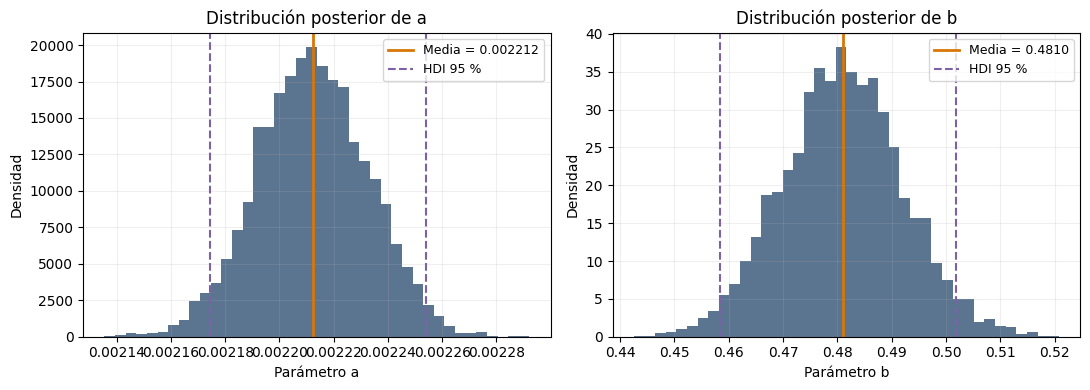

a = 0.002212, HDI 95 %: [0.002174, 0.002254]
b = 0.480987, HDI 95 %: [0.458321, 0.501826]


In [13]:
# Bibliotecas para analizar y graficar los resultados
import numpy as np
import arviz as az
import matplotlib.pyplot as plt

# Obtenemos las muestras posteriores de ambos parámetros
a_muestras = idata.posterior["a"].values.flatten()
b_muestras = idata.posterior["b"].values.flatten()

# Calculamos las medias posteriores
a_media = np.mean(a_muestras)
b_media = np.mean(b_muestras)

# Calculamos los intervalos de mayor densidad del 95 %
a_hdi = az.hdi(a_muestras, hdi_prob=0.95)
b_hdi = az.hdi(b_muestras, hdi_prob=0.95)

# Preparamos las gráficas
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

parametros = [
    ("a", a_muestras, a_media, a_hdi, ".6f"),
    ("b", b_muestras, b_media, b_hdi, ".4f")
]

for ax, (nombre, muestras, media, hdi, formato) in zip(axes, parametros):

    # Distribución posterior
    ax.hist(
        muestras,
        bins=40,
        density=True,
        color="#24476B",
        alpha=0.75
    )

    # Media posterior
    ax.axvline(
        media,
        color="#D97706",
        linestyle="-",
        linewidth=2,
        label=f"Media = {media:{formato}}"
    )

    # Límites del intervalo de credibilidad
    ax.axvline(
        hdi[0],
        color="#7B61A8",
        linestyle="--",
        label="HDI 95 %"
    )

    ax.axvline(
        hdi[1],
        color="#7B61A8",
        linestyle="--"
    )

    ax.set_title(f"Distribución posterior de {nombre}")
    ax.set_xlabel(f"Parámetro {nombre}")
    ax.set_ylabel("Densidad")
    ax.grid(alpha=0.2)
    ax.legend(fontsize=9)

plt.tight_layout()
plt.show()

# Mostramos los valores estimados
print(f"a = {a_media:.6f}, HDI 95 %: [{a_hdi[0]:.6f}, {a_hdi[1]:.6f}]")
print(f"b = {b_media:.6f}, HDI 95 %: [{b_hdi[0]:.6f}, {b_hdi[1]:.6f}]")

**Observación:** Las distribuciones posteriores se concentran alrededor de $a=0.002212$ y $b=0.480987$. Los intervalos de credibilidad del 95 % permiten observar la incertidumbre de ambas estimaciones.

Estos resultados nos proporcionan los valores de los parámetros que utilizaremos para analizar el ajuste del modelo SIR.

<h2><font color="#D97706">11. Distribución posterior conjunta de los parámetros</font></h2>

Hasta ahora analizamos las distribuciones de $a$ y $b$ por separado. Ahora representaremos su distribución conjunta para observar la relación entre ambos parámetros.

La gráfica de contornos permitirá identificar las combinaciones de $a$ y $b$ con mayor densidad posterior. Representaremos regiones de credibilidad aproximadas del 50 % y 95 %.

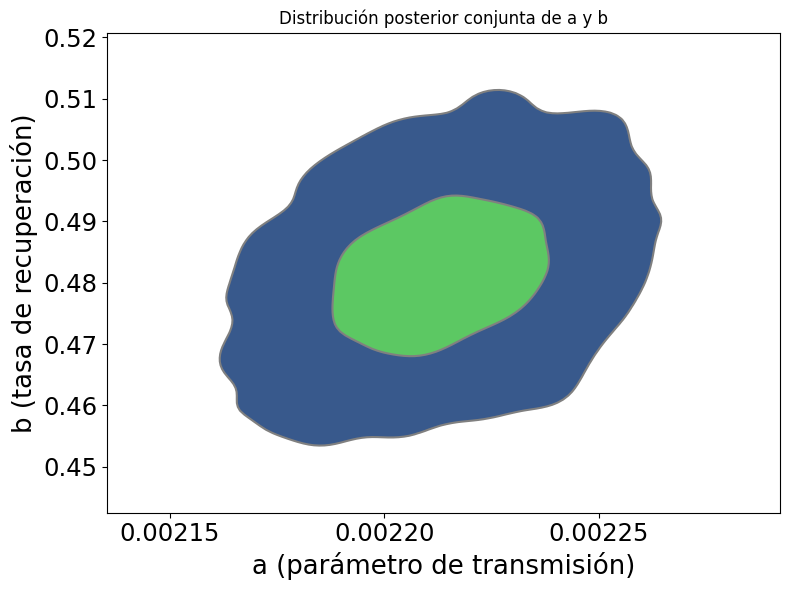

Correlación posterior entre a y b: 0.3178


In [16]:
# Bibliotecas para analizar y graficar la distribución conjunta
import arviz as az
import numpy as np
import matplotlib.pyplot as plt

# Graficamos la distribución posterior conjunta de a y b
az.plot_pair(
    idata,
    var_names=["a", "b"],
    kind="kde",
    marginals=False,
    figsize=(8, 6),
    kde_kwargs={
        "hdi_probs": [0.5, 0.95],
        "contourf_kwargs": {"cmap": "viridis"}
    }
)

plt.title("Distribución posterior conjunta de a y b")
plt.xlabel("a (parámetro de transmisión)")
plt.ylabel("b (tasa de recuperación)")
# Reducimos la cantidad de valores en el eje horizontal
plt.locator_params(axis="x", nbins=5)
plt.tight_layout()
plt.show()

# Calculamos la correlación entre ambos parámetros
correlacion = np.corrcoef(a_muestras, b_muestras)[0, 1]

print(f"Correlación posterior entre a y b: {correlacion:.4f}")

**Observación:** La gráfica muestra que los valores de $a$ y $b$ se concentran principalmente en la región verde, mientras que la región azul abarca una mayor variedad de valores posibles. La forma inclinada indica que ambos parámetros tienden a aumentar juntos, aunque esta relación no es muy fuerte, ya que la correlación obtenida es de $0.3178$.

<h2><font color="#D97706">12. Ajuste bayesiano del modelo SIR</font></h2>

Una vez estimados los parámetros $a$ y $b$, compararemos el número de infectados que predice el modelo SIR con los datos observados.

Utilizaremos las muestras posteriores obtenidas con PyMC para representar la curva estimada y su incertidumbre.

En la gráfica distinguiremos:

- **Curva ajustada:** mediana de los infectados esperados.
- **Intervalo de credibilidad del 95 %:** muestra la incertidumbre de la curva debido a la estimación de los parámetros.
- **Intervalo predictivo del 95 %:** incorpora también la variabilidad de los datos según la distribución de Poisson.

Esto nos permitirá revisar qué tan bien se ajusta el modelo al comportamiento del brote.

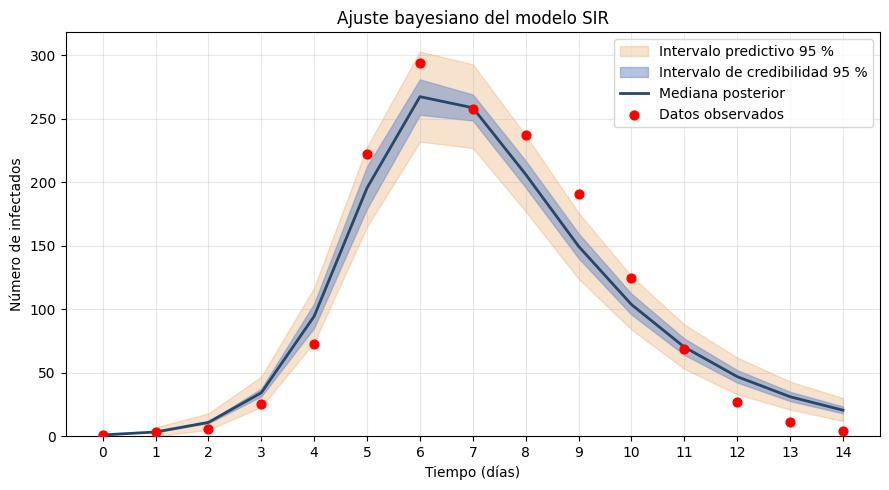

In [17]:
# Bibliotecas para calcular y graficar los resultados
import numpy as np
import matplotlib.pyplot as plt

# Recuperamos los infectados esperados de las muestras posteriores
muestras_I = idata.posterior["I_modelo"].values

# Unimos las cuatro cadenas en un solo arreglo
muestras_I = muestras_I.reshape(-1, len(t) - 1)

# Calculamos la mediana de la curva ajustada
I_mediana = np.median(muestras_I, axis=0)

# Intervalo de credibilidad puntual del 95 %
lim_inf, lim_sup = np.percentile(
    muestras_I, [2.5, 97.5], axis=0
)

# Generamos observaciones posibles con la distribución de Poisson
rng = np.random.default_rng(42)
muestras_pred = rng.poisson(muestras_I)

# Intervalo predictivo puntual del 95 %
pred_inf, pred_sup = np.percentile(
    muestras_pred, [2.5, 97.5], axis=0
)

# Agregamos la condición inicial a la curva estimada
I_ajustada = np.r_[I0, I_mediana]

# Graficamos los resultados
plt.figure(figsize=(9, 5))

# Banda predictiva
plt.fill_between(
    t[1:], pred_inf, pred_sup,
    color="#E6A15A", alpha=0.3,
    label="Intervalo predictivo 95 %"
)

# Incertidumbre de la curva
plt.fill_between(
    t[1:], lim_inf, lim_sup,
    color="#7692C7", alpha=0.55,
    label="Intervalo de credibilidad 95 %"
)

# Curva ajustada
plt.plot(
    t, I_ajustada,
    color="#24476B", linewidth=2,
    label="Mediana posterior"
)

# Datos observados
plt.scatter(
    t, I_obs,
    color="red", s=40, zorder=3,
    label="Datos observados"
)

plt.title("Ajuste bayesiano del modelo SIR")
plt.xlabel("Tiempo (días)")
plt.ylabel("Número de infectados")

plt.xticks(t)
plt.ylim(bottom=0)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

<h3><font color="#D97706">12.1. Comparación con los datos observados</font></h3>

Para complementar la gráfica, calcularemos el error cuadrático medio (RMSE) entre los infectados observados y la mediana de la curva ajustada.

También contaremos cuántos registros de los días 1 al 14 se encuentran dentro del intervalo predictivo del 95 %.

In [18]:
# Biblioteca para realizar los cálculos numéricos
import numpy as np

# Error cuadrático medio de la curva ajustada
rmse = np.sqrt(
    np.mean((I_obs[1:] - I_mediana)**2)
)

# Contamos las observaciones dentro del intervalo predictivo
dentro = (
    (I_obs[1:] >= pred_inf) &
    (I_obs[1:] <= pred_sup)
)

n_dentro = np.sum(dentro)

print(f"RMSE del ajuste: {rmse:.4f} infectados")
print(f"Datos dentro del intervalo predictivo: {n_dentro} de 14")

RMSE del ajuste: 20.9738 infectados
Datos dentro del intervalo predictivo: 9 de 14


**Observación:** La curva ajustada sigue el comportamiento general del brote, aunque presenta diferencias con los datos observados, especialmente en los últimos días, donde estima más infectados de los registrados.

El RMSE fue de 20.9738 infectados y 9 de los 14 datos quedaron dentro del intervalo predictivo del 95 %. Esto indica que el modelo logra describir la tendencia del brote, pero tiene algunas limitaciones para reproducir todos los registros.

<h2><font color="#D97706">13. Modelo SIR con los parámetros estimados</font></h2>

Utilizaremos las medias posteriores de $a$ y $b$ para resolver nuevamente el sistema SIR.

Esto permitirá observar cómo evolucionan los susceptibles, infectados y recuperados con los parámetros obtenidos mediante inferencia bayesiana.

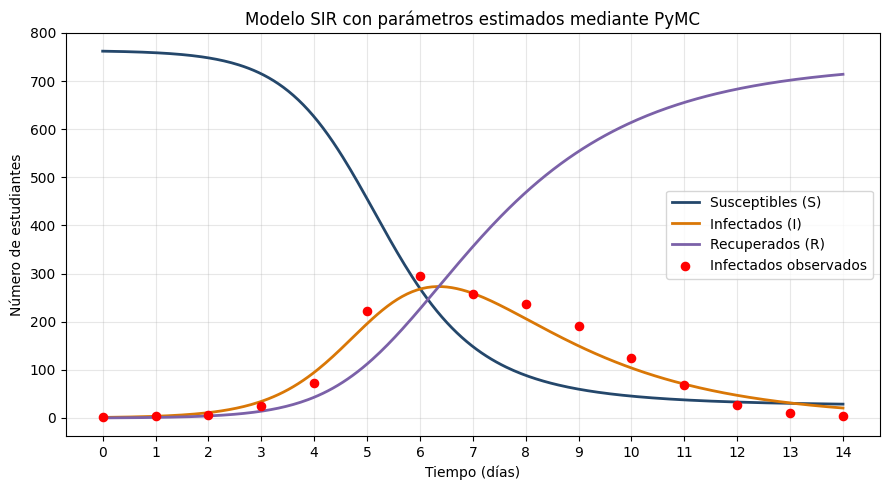

a estimado = 0.002212
b estimado = 0.480987


In [19]:
# Bibliotecas para resolver y graficar el modelo SIR
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# Medias posteriores obtenidas con PyMC
a_est = np.mean(a_muestras)
b_est = np.mean(b_muestras)

# Utilizamos más puntos para obtener curvas suaves
t_fino = np.linspace(0, 14, 300)

# Resolvemos el modelo con los parámetros estimados
solucion_est = solve_ivp(
    sir,
    t_span=(0, 14),
    y0=y0,
    t_eval=t_fino,
    args=(a_est, b_est),
    rtol=1e-8,
    atol=1e-10
)

# Comprobamos que la solución sea correcta
if not solucion_est.success:
    raise RuntimeError(solucion_est.message)

# Separamos las poblaciones
S_est, I_est, R_est = solucion_est.y

# Graficamos las curvas del modelo
plt.figure(figsize=(9, 5))

plt.plot(
    t_fino, S_est,
    color="#24476B",
    linewidth=2,
    label="Susceptibles (S)"
)

plt.plot(
    t_fino, I_est,
    color="#D97706",
    linewidth=2,
    label="Infectados (I)"
)

plt.plot(
    t_fino, R_est,
    color="#7B61A8",
    linewidth=2,
    label="Recuperados (R)"
)

# Agregamos los datos observados
plt.scatter(
    t, I_obs,
    color="red",
    s=35,
    zorder=3,
    label="Infectados observados"
)

plt.title("Modelo SIR con parámetros estimados mediante PyMC")
plt.xlabel("Tiempo (días)")
plt.ylabel("Número de estudiantes")

plt.xticks(t)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Mostramos los parámetros estimados
print(f"a estimado = {a_est:.6f}")
print(f"b estimado = {b_est:.6f}")

**Observación:** La gráfica muestra que los susceptibles disminuyen conforme avanza el brote, mientras que los recuperados aumentan. Los infectados alcanzan un máximo alrededor del día 6 y después comienzan a disminuir.

La curva de infectados sigue una tendencia similar a los datos observados, aunque en los últimos días estima más infectados de los registrados.

<h2><font color="#D97706">14. Comparación de los parámetros estimados</font></h2>

Compararemos las medias posteriores obtenidas mediante PyMC con los parámetros reportados por el método de algoritmos genéticos en el artículo.

Esta comparación permitirá observar las diferencias entre ambas estimaciones, considerando que nuestro procedimiento utiliza una verosimilitud de Poisson.

In [20]:
# Biblioteca para organizar los resultados
import pandas as pd

# Comparamos los parámetros del artículo con los de PyMC
comparacion = pd.DataFrame({
    "Parámetro": ["a", "b"],
    "Algoritmos genéticos": [a_ref, b_ref],
    "PyMC (media posterior)": [a_est, b_est]
})

# Mostramos los valores con seis decimales
print(comparacion.to_string(index=False, float_format="%.6f"))

Parámetro  Algoritmos genéticos  PyMC (media posterior)
        a              0.002050                0.002212
        b              0.435520                0.480987


**Observación:** Los parámetros estimados mediante PyMC son ligeramente mayores que los valores reportados con algoritmos genéticos. Aunque existen diferencias, ambos métodos proporcionan valores cercanos para $a$ y $b$. Esto indica que las estimaciones son similares, considerando que se utilizaron procedimientos de ajuste diferentes.

<h2><font color="#D97706">15. Conclusión</font></h2>
Mediante el enfoque bayesiano y la biblioteca PyMC se estimaron los parámetros del modelo SIR, obteniendo $a=0.002212$ y $b=0.480987$. Las cuatro cadenas presentaron una buena convergencia y el modelo logró reproducir la tendencia general del brote, aunque mostró algunas diferencias con los datos observados, principalmente en los últimos días.

En comparación con el ajuste mediante algoritmos genéticos, **el enfoque bayesiano resultó más completo para nuestro análisis**, ya que permitió conocer la incertidumbre de los parámetros mediante sus distribuciones posteriores e intervalos de credibilidad. Como explican Sivia y Skilling, la distribución posterior combina la información previa con los datos observados, lo que permite evaluar qué tan confiables son las estimaciones.

Por lo tanto, aunque no podemos afirmar que el ajuste bayesiano tuvo un menor error, sí proporcionó más información para interpretar los parámetros y sus posibles valores. Esto nos permitió comprender mejor los resultados y reconocer las limitaciones del modelo SIR para describir el brote.